<a href="https://colab.research.google.com/github/RobertoSonzini/NAML_project/blob/LSMT_implementation/LSTM_implementation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import jax
import jax.numpy as jnp
from jax import grad, jit, vmap, lax
from jax import random

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
import torch
from torch import nn
import math
from sklearn.preprocessing import MinMaxScaler

In [4]:
print(jax.devices())

[CpuDevice(id=0)]


In [5]:
file_path = '/content/drive/MyDrive/ProgettoNAML/all_stocks_5yr.csv'
drive.mount('/content/drive')

df = pd.read_csv(file_path)
df.head()

%matplotlib inline

from datetime import datetime

df.info()
df

Mounted at /content/drive
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 619040 entries, 0 to 619039
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   date    619040 non-null  object 
 1   open    619029 non-null  float64
 2   high    619032 non-null  float64
 3   low     619032 non-null  float64
 4   close   619040 non-null  float64
 5   volume  619040 non-null  int64  
 6   Name    619040 non-null  object 
dtypes: float64(4), int64(1), object(2)
memory usage: 33.1+ MB


,date,open,high,low,close,volume,Name
0,2013-02-08,15.07,15.12,14.63,14.75,8407500,AAL
1,2013-02-11,14.89,15.01,14.26,14.46,8882000,AAL
2,2013-02-12,14.45,14.51,14.10,14.27,8126000,AAL
3,2013-02-13,14.30,14.94,14.25,14.66,10259500,AAL
4,2013-02-14,14.94,14.96,13.16,13.99,31879900,AAL
...,...,...,...,...,...,...,...
619035,2018-02-01,76.84,78.27,76.69,77.82,2982259,ZTS
619036,2018-02-02,77.53,78.12,76.73,76.78,2595187,ZTS
619037,2018-02-05,76.64,76.92,73.18,73.83,2962031,ZTS
619038,2018-02-06,72.74,74.56,72.13,73.27,4924323,ZTS


In [6]:
def sort_by_date(df):
  return df.sort_values(by='date')

In [7]:
def get_dataframe(df, company_names, moving_average=5):
    input_data_labels = ['high', 'low', 'open', 'volume', 'ma5']
    close_data = ['close']

    mask = df['Name'].isin(company_names)
    df_company = df.loc[mask].copy()

    df_company['ma5'] = df_company['close'].rolling(moving_average).mean()

    df_company = df_company.dropna()

    df_company = sort_by_date(df_company)

    return df_company[input_data_labels], df_company[close_data]

In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# prendo nuovamente i dati

df_company, company_closings = get_dataframe(df, ['AAPL'])
df_company, company_closings = pd.DataFrame(scaler.fit_transform(df_company), columns=df_company.columns, index=df_company.index), pd.DataFrame(scaler.fit_transform(company_closings), columns=company_closings.columns, index=company_closings.index)

length = len(df_company)
split_idx = int(length * 0.9)

df_company_train = df_company.iloc[:split_idx]
df_company_closings_train = company_closings.iloc[:split_idx]
df_company_test = df_company.iloc[split_idx:]
df_company_closings_test = company_closings.iloc[split_idx:]

X_train = df_company_train.to_numpy().astype(np.float32)
y_train = df_company_closings_train.to_numpy().astype(np.float32)
X_test = df_company_test.to_numpy().astype(np.float32)
y_test = df_company_closings_test.to_numpy().astype(np.float32)

In [9]:
from torch.utils.data import Dataset

class MyDataset(Dataset):
    def __init__(self, X_data, y_data, seq_len = 1):
      self.X_data = X_data  # array, tensor o lista di feature
      self.y_data = y_data  # target (opzionale se inferenza)
      self.seq_len = seq_len

    def __len__(self):
      return len(self.y_data) - self.seq_len

    def __getitem__(self, idx):
      x = self.X_data[idx : idx + self.seq_len]
      y = self.y_data[idx + self.seq_len] # il target qui lo prendo solo sul passo successivo (last step)

      # x_tensor = torch.tensor(x)
      # y_tensor = torch.tensor(y)

      return x, y

In [10]:
# per esempio di utilizzo

from torch.utils.data import DataLoader

dataset = MyDataset(X_train, y_train, seq_len = 10)
loader = DataLoader(dataset, batch_size=32, shuffle=False)

In [11]:
def mse_loss(y_pred, y_true):
    return jnp.mean((y_pred - y_true) ** 2)

In [12]:
def sigmoid(x):
    return 1.0 / (1.0 + jnp.exp(-x))

def dsigmoid_from_output(s):
    # s = sigmoid(x)
    return s * (1 - s)

def dtanh_from_output(t):
    # t = tanh(x)
    return 1 - t ** 2

### Capitolo medievale

In [ ]:
class LSTM_old:
  '''
    input_size: numero di feature del singolo sample
    hidden_size: numero di celle di memoria. In pratica si tratta di specificare la grandezza del layer che contiene le celle LSTM.
    output_size: numero di valori di output.
  '''
  def __init__(self, input_size, hidden_size, output_size):
    self.input_size = input_size
    self.hidden_size = hidden_size
    self.output_size = output_size

    # Output layer
    self.V = np.random.uniform(-0.1, 0.1, (output_size, hidden_size))
    self.b_out = np.zeros((output_size, 1))

    # Forget gate
    self.U_f = np.random.uniform(-0.1, 0.1, (self.hidden_size, self.input_size))
    self.W_f = np.random.uniform(-0.1, 0.1, (self.hidden_size, self.hidden_size))
    self.b_f = np.ones((hidden_size, 1)) # aiutiamo a ricordare all'inizio settando il valore a 1

    # Input gate
    self.U_i = np.random.uniform(-0.1, 0.1, (hidden_size, input_size))
    self.W_i = np.random.uniform(-0.1, 0.1, (hidden_size, hidden_size))
    self.b_i = np.zeros((hidden_size, 1))

    # External input gate (Candidate)
    self.U_g = np.random.uniform(-0.1, 0.1, (hidden_size, input_size))
    self.W_g = np.random.uniform(-0.1, 0.1, (hidden_size, hidden_size))
    self.b_g = np.zeros((hidden_size, 1))

    # Output gate
    self.U_o = np.random.uniform(-0.1, 0.1, (hidden_size, input_size))
    self.W_o = np.random.uniform(-0.1, 0.1, (hidden_size, hidden_size))
    self.b_o = np.zeros((hidden_size, 1))

    # Initial states
    self.h = np.zeros((hidden_size, 1))
    self.s = np.zeros((hidden_size, 1))

  def forward_step(self, x_t):
    i_t = sigmoid(np.dot(self.U_i, x_t) + np.dot(self.W_i, self.h) + self.b_i)
    f_t = sigmoid(np.dot(self.U_f, x_t) + np.dot(self.W_f, self.h) + self.b_f)
    g_t = np.tanh(np.dot(self.U_g, x_t) + np.dot(self.W_g, self.h) + self.b_g)
    o_t = sigmoid(np.dot(self.U_o, x_t) + np.dot(self.W_o, self.h) + self.b_o)

    self.s = f_t * self.s + i_t * g_t
    self.h = o_t * np.tanh(self.s)

    return self.h, self.s

  def forward(self, X):
    """
    X: array di dimensione (seq_len, input_size)
    Ritorna:
        Y_seq: array di dimensione (seq_len, output_size)
    """
    Y_seq = []

    for t in range(X.shape[0]):
        x_t = X[t].reshape(-1, 1)
        h_t, _ = self.forward_step(x_t)

        # Output layer
        y_t = np.dot(self.V, h_t) + self.b_out
        Y_seq.append(y_t)

    # Converti in array (seq_len, output_size)
    Y_seq = np.hstack(Y_seq).T

    return Y_seq



In [ ]:
class LSTM_not_optimized:
    def __init__(self, key, input_size, hidden_size, output_size, loss_function):
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.loss_function = loss_function
        self.key = key

        # Split the key for different initializations
        keys = jax.random.split(self.key, 9)

        # Inizializzazione pesi
        self.params = {
            'U_f': jax.random.uniform(keys[0], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_f': jax.random.uniform(keys[1], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_f': jnp.ones((hidden_size, 1)),

            'U_i': jax.random.uniform(keys[2], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_i': jax.random.uniform(keys[3], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_i': jnp.zeros((hidden_size, 1)),

            'U_g': jax.random.uniform(keys[4], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_g': jax.random.uniform(keys[5], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_g': jnp.zeros((hidden_size, 1)),

            'U_o': jax.random.uniform(keys[6], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_o': jax.random.uniform(keys[7], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_o': jnp.zeros((hidden_size, 1)),

            'V': jax.random.uniform(keys[8], (output_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_out': jnp.zeros((output_size, 1)),
        }

    def forward_step(self, params, x_t, h_prev, s_prev):
        i_t = sigmoid(params['U_i'] @ x_t + params['W_i'] @ h_prev + params['b_i'])
        f_t = sigmoid(params['U_f'] @ x_t + params['W_f'] @ h_prev + params['b_f'])
        g_t = jnp.tanh(params['U_g'] @ x_t + params['W_g'] @ h_prev + params['b_g'])
        o_t = sigmoid(params['U_o'] @ x_t + params['W_o'] @ h_prev + params['b_o'])

        s_t = f_t * s_prev + i_t * g_t
        h_t = o_t * jnp.tanh(s_t)

        y_t = params['V'] @ h_t + params['b_out']
        return h_t, s_t, y_t

    def forward(self, params, X):
        h = jnp.zeros((self.hidden_size, 1))
        s = jnp.zeros((self.hidden_size, 1))
        Y_seq = []

        for t in range(X.shape[0]):
            x_t = X[t].reshape(-1, 1)
            h, s, y_t = self.forward_step(params, x_t, h, s)
            Y_seq.append(y_t)

        return jnp.hstack(Y_seq).T  # (seq_len, output_size)

    def loss(self, params, X, Y_true):
        Y_pred = self.forward(params, X)
        return self.loss_function(Y_pred, Y_true)

    def backward(self, X, Y_true, lr=0.01):
        # JAX calcola automaticamente i gradienti
        grads = jax.grad(self.loss)(self.params, X, Y_true)
        # Aggiorna pesi
        for key in self.params.keys():
            self.params[key] = self.params[key] - lr * grads[key]

In [ ]:
class LSTM:
    def __init__(self, key, input_size, hidden_size, output_size, loss_function):
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.loss_function = loss_function
        self.key = key

        # Split the key for different initializations
        keys = jax.random.split(self.key, 9)

        # Inizializzazione pesi
        self.params = {
            'U_f': jax.random.uniform(keys[0], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_f': jax.random.uniform(keys[1], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_f': jnp.ones((hidden_size, )),

            'U_i': jax.random.uniform(keys[2], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_i': jax.random.uniform(keys[3], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_i': jnp.zeros((hidden_size, )),

            'U_g': jax.random.uniform(keys[4], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_g': jax.random.uniform(keys[5], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_g': jnp.zeros((hidden_size, )),

            'U_o': jax.random.uniform(keys[6], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_o': jax.random.uniform(keys[7], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_o': jnp.zeros((hidden_size, )),

            'V': jax.random.uniform(keys[8], (output_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_out': jnp.zeros((output_size, )),
        }

    @jit
    def forward_step(params, x_t, h_prev, s_prev):
        i_t = sigmoid(params['U_i'] @ x_t + params['W_i'] @ h_prev + params['b_i'])
        f_t = sigmoid(params['U_f'] @ x_t + params['W_f'] @ h_prev + params['b_f'])
        g_t = jnp.tanh(params['U_g'] @ x_t + params['W_g'] @ h_prev + params['b_g'])
        o_t = sigmoid(params['U_o'] @ x_t + params['W_o'] @ h_prev + params['b_o'])

        s_t = f_t * s_prev + i_t * g_t
        h_t = o_t * jnp.tanh(s_t)

        y_t = params['V'] @ h_t + params['b_out']
        return h_t, s_t, y_t

    @jit
    def forward(params, X):
      # X: (seq_len, input_size)
      h0 = jnp.zeros((self.hidden_size, ))
      s0 = jnp.zeros((self.hidden_size, ))

      def step_scan(carry, x_t):
        h_prev, s_prev = carry
        h_t, s_t, y_t = forward_step(params, x_t, h_prev, s_prev)
        return (h_t, s_t), y_t

      (h_final, s_final), Y_seq = lax.scan(step_scan, (h0, s0), X)
      return jnp.stack(Y_seq, axis=0)  # (seq_len, output_size)

    @jit
    def forward_batch(self, params, X_batch):
      # X_batch: (batch_size, seq_len, input_size)
      return vmap(lambda X_seq: self.forward(params, X_seq))(X_batch)

    @jit
    def loss(self, params, X, Y_true):
        Y_pred = self.forward(params, X)
        return self.loss_function(Y_pred, Y_true)

    @jit
    def backward_batch(self, params, X_batch, Y_batch, lr=0.01):
      # Funzione pura per il grad
      def batch_loss(p):
        return jnp.mean(vmap(lambda X_seq, Y_seq: self.loss(p, X_seq, Y_seq))
                        (X_batch, Y_batch))

      grads = jax.grad(batch_loss)(params)

      # Aggiorna i parametri in modo puro
      new_params = {k: params[k] - lr * grads[k] for k in params.keys()}
      return new_params

In [ ]:
# hyperparameters
input_size = 5
hidden_size = 32
num_epochs = 500
lr = 0.001
seq_len = 40
output_size = 1

key = random.PRNGKey(0)
model = LSTM(key, input_size, hidden_size, output_size, loss_function=mse_loss)

In [ ]:
def train_LSTM(model, X_train, y_train, seq_len, batch_size=32, learning_rate=0.001, epochs=500):
    """
    Train the LSTM using a PyTorch-style DataLoader interno.
    X_train, y_train: dati di training
    seq_len: lunghezza delle sequenze
    batch_size: dimensione del batch
    learning_rate: learning rate
    epochs: numero di epoche
    """
    # Crea dataset e loader
    dataset = MyDataset(X_train, y_train, seq_len=seq_len)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)

    losses = []

    for epoch in range(epochs):
        epoch_loss = 0.0

        for i, (samples, labels) in enumerate(loader):
            # Converti da PyTorch Tensor a JAX numpy array
            # Ensure samples and labels are float32 for compatibility with JAX
            X_batch = jnp.array(samples, dtype=jnp.float32)
            y_batch = jnp.array(labels, dtype=jnp.float32)

            # questo perchè per ora opero senza batches
            # X_batch = jnp.squeeze(X_batch, axis = 0)
            # y_batch = jnp.squeeze(y_batch, axis = 0)

            model.params = model.backward_batch(model.params, X_batch, y_batch, lr=learning_rate)

            # Calcola la loss del batch per monitoraggio
            # Calcola la loss del batch per monitoraggio
            batch_loss = jnp.mean(
                jax.vmap(lambda X_seq, Y_seq: model.loss(model.params, X_seq, Y_seq))(
                    X_batch, y_batch
                )
            )
            epoch_loss += batch_loss

        avg_loss = epoch_loss / len(loader)
        losses.append(avg_loss)

        print(f'Epoch [{epoch}/{epochs}], Loss: {avg_loss:.4f} [{datetime.now()}]')

    return losses

In [ ]:
losses = train_LSTM(model, X_train, y_train, seq_len=seq_len, learning_rate=lr, epochs=num_epochs)

TypeError: Error interpreting argument to <function LSTM.loss at 0x7f27705751c0> as an abstract array. The problematic value is of type <class '__main__.LSTM'> and was passed to the function at path self.
This typically means that a jit-wrapped function was called with a non-array argument, and this argument was not marked as static using the static_argnums or static_argnames parameters of jax.jit.

In [ ]:
@jit
def forward_step(params, x_t, h_prev, s_prev):
    i_t = sigmoid(params['U_i'] @ x_t + params['W_i'] @ h_prev + params['b_i'])
    f_t = sigmoid(params['U_f'] @ x_t + params['W_f'] @ h_prev + params['b_f'])
    g_t = jnp.tanh(params['U_g'] @ x_t + params['W_g'] @ h_prev + params['b_g'])
    o_t = sigmoid(params['U_o'] @ x_t + params['W_o'] @ h_prev + params['b_o'])

    s_t = f_t * s_prev + i_t * g_t
    h_t = o_t * jnp.tanh(s_t)

    y_t = params['V'] @ h_t + params['b_out']
    return h_t, s_t, y_t


@jit
def forward( params, X, hidden_size):
  # X: (seq_len, input_size)
  h0 = jnp.zeros((hidden_size, ))
  s0 = jnp.zeros((hidden_size, ))

  def step_scan(carry, x_t):
    h_prev, s_prev = carry
    h_t, s_t, y_t = forward_step(params, x_t, h_prev, s_prev)
    return (h_t, s_t), y_t

  (h_final, s_final), Y_seq = lax.scan(step_scan, (h0, s0), X)
  return jnp.stack(Y_seq, axis=0)  # (seq_len, output_size)


@jit
def loss(params, X, Y_true, loss_function, hidden_size):
    Y_pred = forward(params, X, hidden_size)
    return loss_function(Y_pred, Y_true)

In [ ]:
class LSTM:
    def __init__(self, key, input_size, hidden_size, output_size, loss_function):
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.loss_function = loss_function
        self.key = key

        # Split the key for different initializations
        keys = jax.random.split(self.key, 9)

        # Inizializzazione pesi
        self.params = {
            'U_f': jax.random.uniform(keys[0], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_f': jax.random.uniform(keys[1], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_f': jnp.ones((hidden_size, )),

            'U_i': jax.random.uniform(keys[2], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_i': jax.random.uniform(keys[3], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_i': jnp.zeros((hidden_size, )),

            'U_g': jax.random.uniform(keys[4], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_g': jax.random.uniform(keys[5], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_g': jnp.zeros((hidden_size, )),

            'U_o': jax.random.uniform(keys[6], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_o': jax.random.uniform(keys[7], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_o': jnp.zeros((hidden_size, )),

            'V': jax.random.uniform(keys[8], (output_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_out': jnp.zeros((output_size, )),
        }



    def forward_batch(self, params, X_batch):
      # X_batch: (batch_size, seq_len, input_size)
      return vmap(lambda X_seq: self.forward(params, X_seq))(X_batch)

    @jit
    def backward_batch(self, params, X_batch, Y_batch, lr=0.01):
      # Funzione pura per il grad
      def batch_loss(p):
        return jnp.mean(vmap(lambda X_seq, Y_seq: self.loss(p, X_seq, Y_seq))
                        (X_batch, Y_batch))

      grads = jax.grad(batch_loss)(params)

      # Aggiorna i parametri in modo puro
      new_params = {k: params[k] - lr * grads[k] for k in params.keys()}
      return new_params

In [ ]:
from jax import jit, vmap

def train_LSTM(model, X_train, y_train, seq_len, batch_size=32, learning_rate=0.001, epochs=500):
    dataset = MyDataset(X_train, y_train, seq_len=seq_len)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)
    size = model.hidden_size
    loss_fn = model.loss_function

    # Definizione di UN training step compilato con JIT
    def train_step(params, X_batch, y_batch):
        def batch_loss(p):
            return jnp.mean(vmap(lambda X_seq, Y_seq: loss(p, X_seq, Y_seq, loss_fn, size))(X_batch, y_batch))

        grads = jax.grad(batch_loss)(params)
        new_params = {k: params[k] - learning_rate * grads[k] for k in params.keys()}
        return new_params, batch_loss(new_params)

    params = model.params
    losses = []

    for epoch in range(epochs):
        epoch_loss = 0.0

        for i, (samples, labels) in enumerate(loader):
            X_batch = jnp.array(samples, dtype=jnp.float32)
            y_batch = jnp.array(labels, dtype=jnp.float32)

            # 🔥 usa la versione compilata del training step

            params, batch_loss = train_step(params, X_batch, y_batch)
            epoch_loss += batch_loss

        model.params = params
        avg_loss = epoch_loss / len(loader)
        losses.append(avg_loss)

        print(f"Epoch [{epoch+1}/{epochs}], Loss: {avg_loss:.4f} [{datetime.now()}]")

    return losses


In [ ]:
losses = train_LSTM(model, X_train, y_train, seq_len=seq_len, learning_rate=lr, epochs=num_epochs)

TypeError: Error interpreting argument to <function loss at 0x7f83d2e8a480> as an abstract array. The problematic value is of type <class 'function'> and was passed to the function at path loss_function.
This typically means that a jit-wrapped function was called with a non-array argument, and this argument was not marked as static using the static_argnums or static_argnames parameters of jax.jit.

# **Nuova implementazione jit-friendly**

In [17]:
import jax
import jax.numpy as jnp
from jax import jit, vmap, lax, grad
from jax.nn import sigmoid

# ---------- FUNZIONI PURE ----------
def forward_step(params, x_t, h_prev, s_prev):
    i_t = sigmoid(params['U_i'] @ x_t + params['W_i'] @ h_prev + params['b_i'])
    f_t = sigmoid(params['U_f'] @ x_t + params['W_f'] @ h_prev + params['b_f'])
    g_t = jnp.tanh(params['U_g'] @ x_t + params['W_g'] @ h_prev + params['b_g'])
    o_t = sigmoid(params['U_o'] @ x_t + params['W_o'] @ h_prev + params['b_o'])

    s_t = f_t * s_prev + i_t * g_t
    h_t = o_t * jnp.tanh(s_t)

    y_t = params['V'] @ h_t + params['b_out']
    return h_t, s_t, y_t

def forward(params, X, hidden_size):
    h0 = jnp.zeros((hidden_size,))
    s0 = jnp.zeros((hidden_size,))

    def step_scan(carry, x_t):
        h_prev, s_prev = carry
        h_t, s_t, y_t = forward_step(params, x_t, h_prev, s_prev)
        return (h_t, s_t), y_t

    (h_final, s_final), Y_seq = lax.scan(step_scan, (h0, s0), X)
    return Y_seq[-1]  # (output_size,)

def forward_batch(params, X_batch, hidden_size):
    return vmap(lambda X_seq: forward(params, X_seq, hidden_size))(X_batch)

def loss(params, X, Y_true, hidden_size, loss_fn):
    Y_pred = forward(params, X, hidden_size)
    return loss_fn(Y_pred, Y_true)

def backward_batch(params, X_batch, Y_batch, hidden_size, lr, loss_fn):
    def batch_loss(p):
        return jnp.mean(vmap(lambda X_seq, Y_seq: loss(p, X_seq, Y_seq, hidden_size, loss_fn))
                        (X_batch, Y_batch))
    grads = grad(batch_loss)(params)
    new_params = {k: params[k] - lr * grads[k] for k in params.keys()}
    return new_params

# ---------- VERSIONI JITTATE ----------
forward_jit = jax.jit(forward, static_argnames=['hidden_size'])
forward_batch_jit = jax.jit(forward_batch, static_argnames=['hidden_size'])
loss_jit = jax.jit(loss, static_argnames=['hidden_size'])
backward_batch_jit = jax.jit(backward_batch, static_argnames=['hidden_size'])


# ---------- WRAPPER ----------
class LSTM_wrapper:
    def __init__(self, key, input_size, hidden_size, output_size, loss_function):
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.loss_function = loss_function
        self.key = key

        # Split the key for different initializations
        keys = jax.random.split(self.key, 9)

        # Inizializzazione pesi
        self.params = {
            'U_f': jax.random.uniform(keys[0], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_f': jax.random.uniform(keys[1], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_f': jnp.ones((hidden_size,)),

            'U_i': jax.random.uniform(keys[2], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_i': jax.random.uniform(keys[3], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_i': jnp.zeros((hidden_size,)),

            'U_g': jax.random.uniform(keys[4], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_g': jax.random.uniform(keys[5], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_g': jnp.zeros((hidden_size,)),

            'U_o': jax.random.uniform(keys[6], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_o': jax.random.uniform(keys[7], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_o': jnp.zeros((hidden_size,)),

            'V': jax.random.uniform(keys[8], (output_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_out': jnp.zeros((output_size,)),
        }

    # ---- Metodi wrapper ----
    def forward_batch(self, params, X_batch):
        return forward_batch_jit(params, X_batch, self.hidden_size)

    def loss(self, params, X, Y_true):
        return loss_jit(params, X, Y_true, self.hidden_size, self.loss_function)

    def backward_batch(self, params, X_batch, Y_batch, lr=0.01):
        return backward_batch_jit(params, X_batch, Y_batch, self.hidden_size, lr, self.loss_function)


In [157]:
# hyperparameters
input_size = 5
hidden_size = 48
num_epochs = 500
# lr = 0.055
# seq_len = 5
lr = 0.055
seq_len = 5
output_size = 1

key = random.PRNGKey(0)
model = LSTM_wrapper(key, input_size, hidden_size, output_size, loss_function=mse_loss)

In [158]:
from datetime import datetime
import jax
import jax.numpy as jnp
from jax import jit, grad

# ---------- TRAIN STEP JITTATO ----------
def train_step(params, X_batch, Y_batch, lr, model):
    """
    Esegue un passo di training su un batch jittato.
    """
    def batch_loss(p):
        Y_pred = model.forward_batch(p, X_batch)
        return jnp.mean((Y_pred - Y_batch) ** 2)  # MSE, puoi sostituire con loss personalizzata

    grads = grad(batch_loss)(params)
    new_params = jax.tree_map(lambda p, g: p - lr * g, params, grads)
    return new_params

train_step_jit = jax.jit(train_step, static_argnames='model')

# ---------- TRAIN LOOP ----------
def train_LSTM(model, X_train, y_train, seq_len, batch_size=32, learning_rate=0.001, epochs=500):
    """
    Training loop per la LSTM con batch jittato.
    X_train: array (num_samples, seq_len, input_size)
    y_train: array (num_samples, seq_len, output_size)
    """
    # Crea dataset e loader
    dataset = MyDataset(X_train, y_train, seq_len=seq_len)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

    losses = []

    for epoch in range(epochs):
        epoch_loss = 0.0

        for samples, labels in loader:
            # Converti batch in JAX arrays
            X_batch = jnp.array(samples, dtype=jnp.float32)
            Y_batch = jnp.array(labels, dtype=jnp.float32)

            # Aggiorna parametri con train_step jittato
            model.params = train_step_jit(model.params, X_batch, Y_batch, learning_rate, model)

            # Loss del batch per monitoraggio
            Y_pred = model.forward_batch(model.params, X_batch)
            batch_loss = jnp.mean((Y_pred - Y_batch) ** 2)
            epoch_loss += batch_loss

        avg_loss = epoch_loss / len(loader)
        losses.append(avg_loss)

        if (epoch+1) % 50 == 0:
            print(f'Epoch [{epoch+1}/{epochs}], Loss: {avg_loss:.6f} [{datetime.now()}]')

    return losses


In [159]:
losses = train_LSTM(model, X_train, y_train, seq_len=seq_len, learning_rate=lr, epochs=num_epochs)

Epoch [50/500], Loss: 0.005230 [2025-08-20 10:42:20.639395]
Epoch [100/500], Loss: 0.004442 [2025-08-20 10:42:25.198310]
Epoch [150/500], Loss: 0.003951 [2025-08-20 10:42:31.813026]
Epoch [200/500], Loss: 0.003656 [2025-08-20 10:42:36.417090]
Epoch [250/500], Loss: 0.003451 [2025-08-20 10:42:41.636970]
Epoch [300/500], Loss: 0.003333 [2025-08-20 10:42:47.677033]
Epoch [350/500], Loss: 0.003294 [2025-08-20 10:42:52.268886]
Epoch [400/500], Loss: 0.003214 [2025-08-20 10:42:58.973652]
Epoch [450/500], Loss: 0.003205 [2025-08-20 10:43:03.555806]
Epoch [500/500], Loss: 0.003203 [2025-08-20 10:43:08.161112]


In [160]:
def test_LSTM(model, X_test, y_test, seq_len, loss_function, batch_size=32):
    total_loss = 0
    preds = []
    actuals = []

    dataset = MyDataset(X_test, y_test, seq_len=seq_len)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)

    for x_batch, y_batch in loader:
        X_batch = jnp.array(x_batch, dtype=jnp.float32)
        Y_batch = jnp.array(y_batch, dtype=jnp.float32)

        Y_pred = model.forward_batch(model.params, X_batch)

        loss = jnp.mean((Y_pred - Y_batch)**2)
        total_loss += loss * X_batch.shape[0]

        preds.extend(np.array(Y_pred))
        actuals.extend(np.array(Y_batch))

    avg_loss = total_loss / len(loader.dataset)
    print(f"Test Loss: {avg_loss:.4f}")

    return preds, actuals

In [161]:
preds, actuals = test_LSTM(model, X_test, y_test, seq_len=seq_len, loss_function=mse_loss)

Test Loss: 0.0062


In [162]:
def plot_predictions(preds, actuals):
  plt.plot(actuals, label='True')
  plt.plot(preds, label='Predicted')
  plt.legend()
  plt.title('Comparison between prediction and true value')
  plt.show()

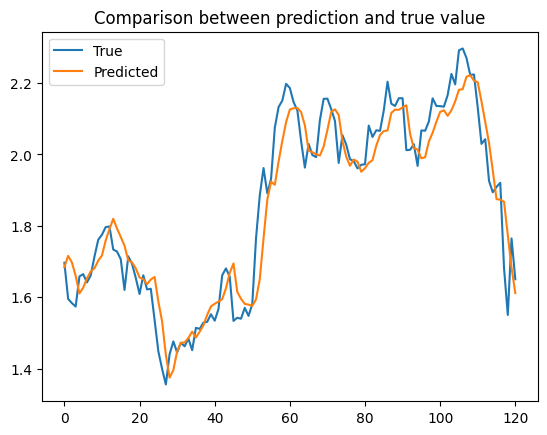

In [163]:
plot_predictions(preds, actuals)